# Notebook 03: Indivisibility — Where Quantum Processes Live

**Goal:** Construct a process that fails the divisibility test and understand
exactly why — negative entries in the intermediate matrix.

By the end of this notebook you will be able to:
- Construct an indivisible stochastic process from a qubit unitary
- Identify which failure mode is triggered and at which times
- Compute the indivisibility signature and interpret its value

---
> ### 📓 Annotated study copy
>
> Working copy of `03_indivisibility.ipynb`. Added sections are marked **📖 In depth**,
> **🔍 Reading the code**, and **🔧 Corrected**.
>
> **⚠️ This copy contains substantive corrections, not just additions.** The original
> notebook mislabels its central example in a way that contradicts its own prose. Two
> cells have been rewritten:
>
> | cell | problem | fix |
> |---|---|---|
> | "Step transition matrices" | printed `proc.transitions[1]` as *"T(t2→t3), dt=0.2618"* — but $\lvert U(0.2618)\rvert^2 = \begin{smallmatrix}0.983 & 0.017\\ 0.017 & 0.983\end{smallmatrix}$, which is perfectly valid. The negative matrix shown is the **derived** intermediate, not a step computed from the unitary. | separates the *given* absolute matrices from the *derived* intermediate, and labels each correctly |
> | ω sweep | linear axis with a 16.3 spike flattens everything else; 29 of 50 points sit at exactly 0 with no explanation | log axis, singular/zero points marked, caveats spelled out |
>
> Companion to `01_stochastic_processes_annotated.ipynb` and `02_divisibility_annotated.ipynb`.
---

In [1]:
import sys
import os
sys.path.insert(0, os.path.abspath('..'))
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from isp.quantum import make_qubit_sigmax_process
from isp.divisibility import check_divisibility, indivisibility_signature
from isp.visualization import plot_transition_matrix

## 1. A Process From Quantum Mechanics

Consider a qubit evolving under $H = \frac{\omega}{2}\sigma_x$.
The unitary is:
$$U(dt) = e^{-iH\,dt} = \begin{pmatrix} \cos\tfrac{\omega\,dt}{2} & -i\sin\tfrac{\omega\,dt}{2} \\ -i\sin\tfrac{\omega\,dt}{2} & \cos\tfrac{\omega\,dt}{2} \end{pmatrix}$$

The stochastic transition matrix takes $|U_{ij}|^2$:
$$T(dt) = \begin{pmatrix} \cos^2\tfrac{\omega\,dt}{2} & \sin^2\tfrac{\omega\,dt}{2} \\ \sin^2\tfrac{\omega\,dt}{2} & \cos^2\tfrac{\omega\,dt}{2} \end{pmatrix}$$

Each column sums to 1. All entries are non-negative. Looks perfectly classical — or does it?

### 📖 In depth: where exactly does the quantumness enter?

The markdown above ends with *"Looks perfectly classical — or does it?"* — which is the right question, but the answer is more specific than "it isn't."

#### The setup is genuinely, unimpeachably classical

Everything handed to us is a legitimate probabilistic object:

* $U(t)$ is unitary, so each column is a unit vector;
* therefore $T(t,t_0)_{ij} = |U(t)_{ij}|^2$ has non-negative entries whose columns sum to $\sum_i |U_{ij}|^2 = 1$;
* so **every** $T(t, t_0)$ is a bona fide stochastic matrix, at every time, no exceptions.

There is no sleight of hand. A qubit really does define an honest stochastic process over the two computational-basis states. The next cell verifies this against the closed form.

#### The failure is in composition, not in any individual matrix

Here is the mechanism, and it is worth stating precisely because the original notebook's mislabelling obscures it.

Quantum evolution composes perfectly **at the level of amplitudes**:

$$U(a+b) = U(b)\,U(a) \qquad \text{(exact, to machine precision)}$$

But the map to probabilities, $M \mapsto |M|^2$ entrywise, **does not commute with matrix multiplication**:

$$\big|U(b)\,U(a)\big|^2 \;\neq\; \big|U(b)\big|^2\,\big|U(a)\big|^2$$

Write out one entry to see why:

$$\Big|\sum_k U(b)_{ik}\,U(a)_{kj}\Big|^2 \;=\; \underbrace{\sum_k \big|U(b)_{ik}\big|^2\big|U(a)_{kj}\big|^2}_{\text{the classical, path-summed term}} \;+\; \underbrace{\sum_{k \neq l} U(b)_{ik}U(a)_{kj}\overline{U(b)_{il}U(a)_{lj}}}_{\textbf{cross terms — interference}}$$

The first term is exactly what a stochastic matrix product would give: sum over intermediate states $k$, multiplying probabilities along each path. The second term is the residue of the **relative phases** between paths — the thing $|\cdot|^2$ throws away when applied too early.

> **This is the whole of indivisibility in one line.** Classical probability requires summing over intermediate states. Quantum mechanics sums over intermediate *amplitudes* and squares afterwards. Those differ by the cross terms, and the difference is not a small correction — it is what makes the required intermediate matrix step outside the space of stochastic matrices entirely.

#### Why negative entries specifically

The composite $T(t_3,t_1)$ is fixed by physics — it is $|U(t_3-t_1)|^2$, and it is valid. The first leg $T(t_2,t_1)$ is likewise fixed and valid. So the intermediate is forced:

$$T(t_3,t_2) = T(t_3,t_1)\,T(t_2,t_1)^{-1}$$

If interference has made $T(t_3,t_1)$ *more concentrated* than any classical composition through $t_2$ could produce, the only way to recover it is for the intermediate to **subtract** probability along some paths. Subtracting probability means negative entries. As notebook 01 showed, the column sums survive this untouched — nothing is created or destroyed, it is only pushed below zero and compensated above one.

Negative entries are therefore not a numerical artifact or a modelling failure. They are the precise, quantitative measure of how much interference the classical factorization cannot absorb.

In [2]:
# 🔧 CORRECTED CELL. The original printed proc.transitions[1] under the label
#    "T(t2→t3), dt=0.2618", which is wrong twice over: that matrix is not
#    |U(0.2618)|^2, and calling it a "step transition matrix" contradicts the
#    markdown above. Given and derived objects are now kept separate.

omega = 1.0

# Specific times chosen to expose indivisibility
t1, t2, t3 = 0.0, 3 * np.pi / 4, 5 * np.pi / 6

proc = make_qubit_sigmax_process(omega=omega, times=[t1, t2, t3])

# ---- THE GIVEN DATA: absolute transition matrices from the initial time t1 ----
# These are literally |U(t)|^2 from the formula above. They are what *defines*
# the process, and every one of them is a valid stochastic matrix.
print("GIVEN — absolute transition matrices from t1 (these define the process):\n")
for k, name in [(1, "t2"), (2, "t3")]:
    T = proc.transition_from_to(0, k)
    elapsed = proc.times[k] - t1
    print(f"  T(t1→{name}),  elapsed = {elapsed:.4f}")
    print("   ", str(T.round(4)).replace("\n", "\n    "))
    print(f"    min entry {T.min():+.4f} >= 0   column sums {T.sum(axis=0).round(6)}"
          f"   -> VALID stochastic matrix\n")

# Cross-check against the closed form in the markdown, to prove these really
# are |U|^2 and nothing has been quietly substituted:
theta = omega * (t3 - t1) / 2
closed_form = np.array([[np.cos(theta)**2, np.sin(theta)**2],
                        [np.sin(theta)**2, np.cos(theta)**2]])
print(f"  cross-check T(t1→t3) equals |U(t3)|^2 from the formula: "
      f"{np.allclose(proc.transition_from_to(0, 2), closed_form)}")

print("\n" + "="*70)
print("So far everything is non-negative, exactly as the markdown says.")
print("The trouble appears only when we ask for the matrix BETWEEN t2 and t3.")
print("="*70)

GIVEN — absolute transition matrices from t1 (these define the process):

  T(t1→t2),  elapsed = 2.3562
    [[0.1464 0.8536]
     [0.8536 0.1464]]
    min entry +0.1464 >= 0   column sums [1. 1.]   -> VALID stochastic matrix

  T(t1→t3),  elapsed = 2.6180
    [[0.067 0.933]
     [0.933 0.067]]
    min entry +0.0670 >= 0   column sums [1. 1.]   -> VALID stochastic matrix

  cross-check T(t1→t3) equals |U(t3)|^2 from the formula: True

So far everything is non-negative, exactly as the markdown says.
The trouble appears only when we ask for the matrix BETWEEN t2 and t3.


In [3]:
# 🔧 NEW CELL (replaces the mislabelled half of the original).
#    The DERIVED intermediate, and the real reason it goes negative.

dt_23 = t3 - t2

# (a) What the closed form gives for a gap of this length:
theta_23 = omega * dt_23 / 2
T_naive = np.array([[np.cos(theta_23)**2, np.sin(theta_23)**2],
                    [np.sin(theta_23)**2, np.cos(theta_23)**2]])
print(f"(a) |U(dt={dt_23:.4f})|^2  — the closed form for this gap:")
print("   ", str(T_naive.round(4)).replace("\n", "\n    "))
print(f"    min entry {T_naive.min():+.4f}  ->  perfectly valid.\n")

# (b) What the process ACTUALLY requires to get from t2 to t3:
T_derived = proc.transitions[1]
print("(b) The matrix actually required to carry the process t2 -> t3,")
print("    derived as T(t1→t3) @ inv(T(t1→t2)):")
print("   ", str(T_derived.round(4)).replace("\n", "\n    "))
print(f"    min entry {T_derived.min():+.4f}  <-- NEGATIVE")
print(f"    column sums {T_derived.sum(axis=0).round(6)}  <-- still exactly 1\n")

print(f"    Same matrix? {np.allclose(T_naive, T_derived)}   <-- THE WHOLE POINT.")
print("    The original cell hid this by printing (b) under a label describing (a).\n")

# ---- WHY they differ: the Born map destroys the composition law ----------
print("=" * 70)
print("WHY: |.|^2 does not commute with matrix multiplication.")
print("=" * 70)

def U(t):
    """Unitary for H = (omega/2) sigma_x."""
    th = omega * t / 2
    return np.array([[np.cos(th), -1j*np.sin(th)],
                     [-1j*np.sin(th), np.cos(th)]])

a, b = t2 - t1, t3 - t2

# The unitaries compose perfectly -- quantum evolution IS divisible upstairs:
print(f"\n  unitaries compose exactly:  max|U(a+b) - U(a)U(b)| = "
      f"{np.abs(U(a+b) - U(a) @ U(b)).max():.2e}")

# But their squared moduli do not:
lhs = np.abs(U(a + b))**2          # |U(a+b)|^2   -- the true T(t1→t3)
rhs = np.abs(U(b))**2 @ np.abs(U(a))**2   # what divisibility would demand
print(f"\n  |U(a+b)|^2 =\n   ", str(lhs.round(4)).replace("\n", "\n    "))
print(f"  |U(b)|^2 @ |U(a)|^2 =\n   ", str(rhs.round(4)).replace("\n", "\n    "))
print(f"\n  equal? {np.allclose(lhs, rhs)}   difference = {np.abs(lhs-rhs).max():.4f}")

print("\n  Amplitudes compose; probabilities do not. Taking |.|^2 throws away the")
print("  relative phase, and the phase is exactly what the cross-terms need. The")
print("  gap between those two matrices IS interference -- and forcing the")
print("  factorization to hold anyway is what drives entries negative.")

(a) |U(dt=0.2618)|^2  — the closed form for this gap:
    [[0.983 0.017]
     [0.017 0.983]]
    min entry +0.0170  ->  perfectly valid.

(b) The matrix actually required to carry the process t2 -> t3,
    derived as T(t1→t3) @ inv(T(t1→t2)):
    [[ 1.1124 -0.1124]
     [-0.1124  1.1124]]
    min entry -0.1124  <-- NEGATIVE
    column sums [1. 1.]  <-- still exactly 1

    Same matrix? False   <-- THE WHOLE POINT.
    The original cell hid this by printing (b) under a label describing (a).

WHY: |.|^2 does not commute with matrix multiplication.

  unitaries compose exactly:  max|U(a+b) - U(a)U(b)| = 1.11e-16

  |U(a+b)|^2 =
    [[0.067 0.933]
     [0.933 0.067]]
  |U(b)|^2 @ |U(a)|^2 =
    [[0.1585 0.8415]
     [0.8415 0.1585]]

  equal? False   difference = 0.0915

  Amplitudes compose; probabilities do not. Taking |.|^2 throws away the
  relative phase, and the phase is exactly what the cross-terms need. The
  gap between those two matrices IS interference -- and forcing the
  facto

In [4]:
result = check_divisibility(proc)
print(f"Divisible: {result['divisible']}")
print(f"Failure mode: {result['failure_mode']}")
print(f"At times: {tuple(f'{t:.4f}' for t in result['at_times'])}")
print(f"Message: {result['message']}")

Divisible: False
Failure mode: negative_entries
At times: ('0.0000', '2.3562', '2.6180')
Message: Intermediate matrix T(2.6179938779914944,2.356194490192345) has negative entries: min=-0.112372


In [5]:
# Compute the offending intermediate matrix by hand
T_13 = proc.transition_from_to(0, 2)   # composite T(t1→t3)
T_12 = proc.transition_from_to(0, 1)   # step T(t1→t2)

T_23_candidate = T_13 @ np.linalg.inv(T_12)

print("T(t2→t3) candidate:")
print(T_23_candidate.round(4))
print(f"\nMinimum entry: {T_23_candidate.min():.6f}  ← NEGATIVE")
print(f"Column sums: {T_23_candidate.sum(axis=0).round(6)}")

T(t2→t3) candidate:
[[ 1.1124 -0.1124]
 [-0.1124  1.1124]]

Minimum entry: -0.112372  ← NEGATIVE
Column sums: [1. 1.]


### 🔍 Reading the code: why you keep seeing the same matrix

You have now met $\begin{pmatrix}1.1124 & -0.1124\\ -0.1124 & 1.1124\end{pmatrix}$ three times — as `proc.transitions[1]`, in `check_divisibility()`'s failure message, and as the hand-computed `T_23_candidate` above. That is not a coincidence, and noticing why explains what the test is really doing.

`make_qubit_sigmax_process()` **stores the derived intermediates**. From its own docstring:

```python
# Each stored incremental matrix is T(0→t_{i+1}) @ inv(T(0→t_i)), so that
# transition_from_to(0, k) chains to give the absolute evolution T(0→t_k).
```

So `transitions[i]` is *already* the candidate intermediate for step $i$. When `check_divisibility()` then computes $T(t_1{\to}t_3)\,T(t_1{\to}t_2)^{-1}$, the composition telescopes and hands back exactly `transitions[1]`:

$$\underbrace{\big(T_2\,T_1\big)}_{T(t_1\to t_3)}\;\underbrace{T_1^{-1}}_{T(t_1\to t_2)^{-1}} \;=\; T_2$$

**Consequence worth internalizing:** for any process stored as a chain of composable steps, `check_divisibility()` reduces to *"are the stored step matrices themselves non-negative?"* The inversion machinery cancels out. The test is not discovering some subtle emergent property — it is checking whether the pieces the process was assembled from are legitimate stochastic matrices in the first place.

That sounds deflationary but is exactly right, and it is why the construction in `quantum.py` is the honest one: it does **not** hand the process a set of nice non-negative steps and then find something surprising. It fixes the physically meaningful objects — the absolute matrices $|U(t)|^2$ from $t_0$, all valid — and *derives* the steps. The negativity is forced by the physics, not chosen.

Contrast with notebook 02's first example, where three arbitrary non-negative matrices were supplied directly as steps. That process is divisible by construction and could never have failed. **Which matrices you treat as given decides whether the test has anything to find.**

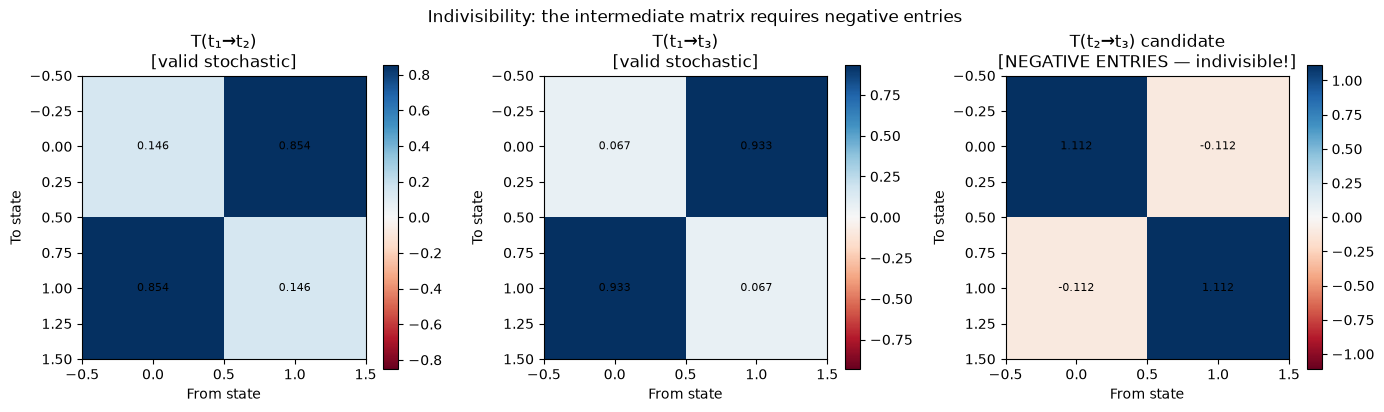

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

plot_transition_matrix(T_12, title="T(t₁→t₂)\n[valid stochastic]", ax=axes[0])
plot_transition_matrix(T_13, title="T(t₁→t₃)\n[valid stochastic]", ax=axes[1])
plot_transition_matrix(T_23_candidate,
                       title="T(t₂→t₃) candidate\n[NEGATIVE ENTRIES — indivisible!]",
                       ax=axes[2])

plt.suptitle("Indivisibility: the intermediate matrix requires negative entries")
plt.tight_layout()
plt.show()

## 2. The Indivisibility Signature

The indivisibility signature measures *how far* a process is from divisible.
It's the magnitude of the most negative entry found across all candidate
intermediate matrices. Zero means classical; positive means quantum territory.

### 🔍 Reading the code: what the signature does and does **not** measure

The markdown above says *"Zero means classical; positive means quantum territory."* That is the right instinct but it overstates what `indivisibility_signature()` actually computes. Four caveats, all of which the ω-sweep below runs straight into.

#### 1. Zero does not mean classical — it means "divisible at the times you sampled"

The signature only inspects the time points in `process.times`. A genuinely quantum process sampled at unlucky times returns exactly $0.0$. In the sweep below, **29 of 50 ω values give a signature of precisely zero**, and not one of them is classical — every one is the same qubit under the same Hamiltonian.

This is Barandes' notion of a **division event**: a process can be perfectly divisible across *some* intervals and fail across others. Indivisibility is a property of the process *and* the times you cut it at. A zero is a failure to detect, not a certificate of classicality.

#### 2. It is unbounded, so it is not a "how quantum" scale

The value is the magnitude of the most negative entry, with no normalization. Since it comes from an inverse, it blows up as $\det T(t_2,t_1) \to 0$. The sweep peaks at **16.35** — meaning an entry of $-1635\%$ — right where the determinant gets small ($|\det| \approx 0.014$). A signature of 16.35 is not "145× more quantum" than 0.112; it mostly reflects a near-singular matrix being inverted.

Treat it as a **detector** (zero vs. non-zero) rather than a **metric** (how far).

#### 3. It silently skips the singular case

Line 88 of `isp/divisibility.py`:

```python
if abs(np.linalg.det(T_ij)) < tol:
    continue          # <-- skipped, contributes nothing
```

Where `check_divisibility()` reports `singular_matrix` (misleadingly, as notebook 02's annotations showed), the signature just steps over it. So the two functions disagree about the same process: one calls it non-divisible, the other scores it 0.0. Neither is really right — the honest answer is "inconclusive at this triple."

#### 4. It is basis-dependent

$T_{ij} = |U_{ij}|^2$ is computed in the computational basis. Change basis and the numbers change — a process indivisible in one basis may look tamer in another. Nothing in the code fixes a preferred basis; it inherits whichever one the unitary was written in. Worth keeping in mind before reading a signature as an intrinsic property of the physics.

---

> **None of this undermines the notebook's conclusion.** A single non-zero signature is sufficient to prove indivisibility, and we have one: $0.112372$, from a `negative_entries` failure, at a well-conditioned triple. The caveats matter for *interpreting magnitudes and zeros*, not for the existence result.

In [7]:
from isp.stochastic import make_markov_chain

L = np.array([[-0.5,  0.3], [0.5, -0.3]])
markov = make_markov_chain(2, L, times=[0.0, 3*np.pi/4, 5*np.pi/6])
quantum = make_qubit_sigmax_process(omega=1.0, times=[0.0, 3*np.pi/4, 5*np.pi/6])

sig_markov  = indivisibility_signature(markov)
sig_quantum = indivisibility_signature(quantum)

print(f"Markov chain signature:  {sig_markov:.6f}  (classical → ~0)")
print(f"Qubit sigma_x signature: {sig_quantum:.6f}  (quantum  → > 0)")

Markov chain signature:  0.000000  (classical → ~0)
Qubit sigma_x signature: 0.112372  (quantum  → > 0)


non-zero (indivisibility detected) : 21 of 50
exactly zero (NOT classical -- just
  divisible at these three times)  : 29 of 50
peak signature 16.35 at omega=1.994, where |det T(t1→t2)| = 0.0144


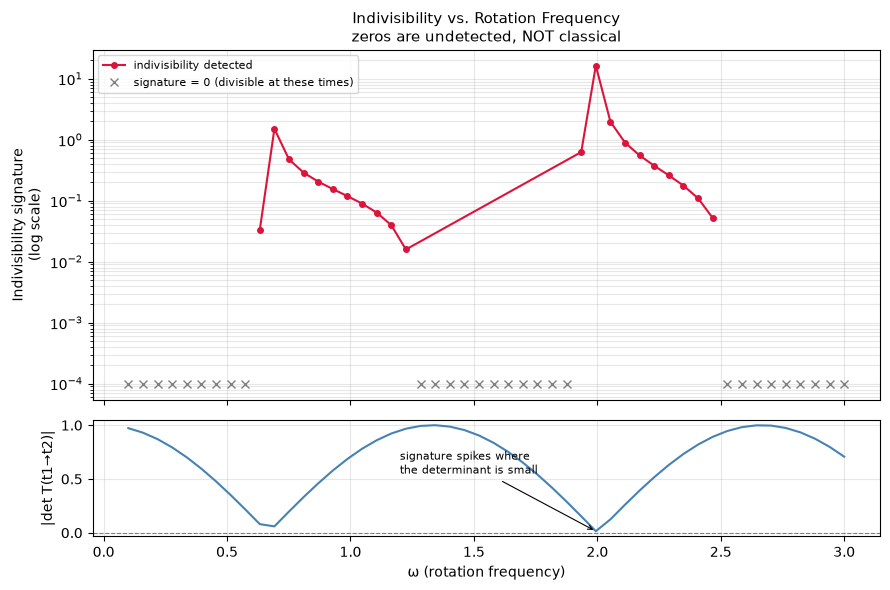


Reading this plot: the red curve shows WHERE the test fires, not 'how
quantum' the system is. The blue panel explains the tall spike -- it is an
ill-conditioned inverse, not a physically more quantum regime. And every
gray x is the same qubit, merely cut at times where it happens to divide.


In [8]:
# 🔧 CORRECTED CELL. The original plotted this on a linear axis, where a single
#    spike of 16.35 flattens everything else into the baseline, and where 29 of
#    50 points sit at exactly zero with no indication that they are undetected
#    rather than classical. Log axis + explicit marking of both.

omegas = np.linspace(0.1, 3.0, 50)
signatures, dets = [], []

for w in omegas:
    p = make_qubit_sigmax_process(omega=w, times=[0.0, 3*np.pi/4, 5*np.pi/6])
    signatures.append(indivisibility_signature(p))
    dets.append(abs(np.linalg.det(p.transition_from_to(0, 1))))

signatures = np.array(signatures)
dets = np.array(dets)
detected = signatures > 0

print(f"non-zero (indivisibility detected) : {detected.sum():>2} of {len(omegas)}")
print(f"exactly zero (NOT classical -- just")
print(f"  divisible at these three times)  : {(~detected).sum():>2} of {len(omegas)}")
print(f"peak signature {signatures.max():.2f} at omega={omegas[signatures.argmax()]:.3f}, "
      f"where |det T(t1→t2)| = {dets[signatures.argmax()]:.4f}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})

ax1.semilogy(omegas[detected], signatures[detected], "o-", ms=4,
             color="crimson", label="indivisibility detected")
ax1.plot(omegas[~detected], np.full((~detected).sum(), 1e-4), "x", ms=6,
         color="gray", label="signature = 0 (divisible at these times)")
ax1.set_ylabel("Indivisibility signature\n(log scale)")
ax1.set_title("Indivisibility vs. Rotation Frequency\n"
              "zeros are undetected, NOT classical", fontsize=11)
ax1.legend(fontsize=8, loc="upper left")
ax1.grid(alpha=0.3, which="both")

ax2.plot(omegas, dets, color="steelblue")
ax2.set_ylabel("|det T(t1→t2)|")
ax2.set_xlabel("ω (rotation frequency)")
ax2.axhline(0, color="gray", ls="--", lw=0.8)
ax2.grid(alpha=0.3)
ax2.annotate("signature spikes where\nthe determinant is small",
             xy=(omegas[signatures.argmax()], dets[signatures.argmax()]),
             xytext=(1.2, 0.55), fontsize=8,
             arrowprops=dict(arrowstyle="->", lw=0.8))

plt.tight_layout()
plt.show()

print("\nReading this plot: the red curve shows WHERE the test fires, not 'how")
print("quantum' the system is. The blue panel explains the tall spike -- it is an")
print("ill-conditioned inverse, not a physically more quantum regime. And every")
print("gray x is the same qubit, merely cut at times where it happens to divide.")

## Summary

- A process can have valid individual transition matrices but still be indivisible
- Indivisibility shows up as negative entries in the *candidate* intermediate matrix
- This is the mathematical gap where quantum mechanics lives
- The indivisibility signature quantifies how deep into "quantum territory" a process is

**Next:** Notebook 04 builds the formal bridge — showing a qubit density matrix
maps directly to an indivisible stochastic process, and the Born rule emerges.